<a href="https://colab.research.google.com/github/mines007/ftth-site-progress-analysis/blob/main/ftth_site_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FTTH Site Progress Analysis
Simulated dataset (no real client data). Questions: (1) Which areas pass ATP first time most often? (2) What defects are most common? (3) How does site size affect build time?

In [8]:
rate = df.groupby('area')['atp_result'].apply(lambda s: (s=='Pass').mean()*100).round(1).sort_values()
print("Lowest pass rate:", rate.index[0], rate.iloc[0], "%")
print("Highest pass rate:", rate.index[-1], rate.iloc[-1], "%")
print("Overall pass rate:", round((df['atp_result']=='Pass').mean()*100, 1), "%")
print("Most common defect:", df[df['defect_type']!='None']['defect_type'].value_counts().idxmax())
print("Size vs days correlation:", round(df['poles'].corr(df['days_to_complete']), 2))

Lowest pass rate: Lekki 50.0 %
Highest pass rate: Ikorodu 100.0 %
Overall pass rate: 70.9 %
Most common defect: Cable sag
Size vs days correlation: 0.65


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('sites.csv', parse_dates=['start_date','end_date'])
df.head()

,site_id,area,poles,cable_km,splicers,riggers,start_date,end_date,atp_result,defect_type,loss_db
0,SITE-001,Ajah,169,5.5,4,3,2026-01-11,2026-01-29,Fail,Dirty connector,26.0
1,SITE-002,Yaba,154,4.5,4,3,2026-02-27,2026-03-15,Pass,NaN,17.9
2,SITE-003,Lekki,178,6.3,4,4,2026-03-20,2026-04-06,Pass,NaN,22.6
3,SITE-004,Ikeja,221,8.5,4,4,2026-02-11,2026-03-10,Fail,Pole alignment,16.5
4,SITE-005,Lekki,224,7.8,4,3,2026-01-29,2026-02-24,Pass,NaN,15.9


## 1. Clean the data

In [2]:
print(df.isna().sum())
print('Duplicates:', df.duplicated().sum())

site_id         0
area            0
poles           0
cable_km        1
splicers        0
riggers         0
start_date      0
end_date        0
atp_result      0
defect_type    39
loss_db         1
dtype: int64
Duplicates: 1


In [3]:
df = df.drop_duplicates()
df['area'] = df['area'].str.strip().str.title()
df['atp_result'] = df['atp_result'].str.strip().str.title()
df['cable_km'] = df['cable_km'].fillna(df['cable_km'].median())
df['loss_db'] = df['loss_db'].fillna(df['loss_db'].median())
df['days_to_complete'] = (df['end_date'] - df['start_date']).dt.days
df.describe()

,poles,cable_km,splicers,riggers,start_date,end_date,loss_db,days_to_complete
count,55.000000,55.000000,55.0,55.000000,55,55,55.000000,55.000000
mean,201.654545,6.910909,4.0,4.036364,2026-03-04 14:50:10.909090816,2026-03-28 16:08:43.636363520,20.418182,24.054545
min,151.000000,4.300000,4.0,3.000000,2026-01-05 00:00:00,2026-01-28 00:00:00,14.700000,16.000000
25%,175.000000,5.900000,4.0,4.000000,2026-02-09 00:00:00,2026-03-07 12:00:00,16.600000,21.000000
50%,201.000000,6.900000,4.0,4.000000,2026-03-10 00:00:00,2026-04-03 00:00:00,20.100000,25.000000
75%,224.500000,7.900000,4.0,5.000000,2026-03-31 00:00:00,2026-04-21 00:00:00,23.400000,26.500000
max,255.000000,9.900000,4.0,5.000000,2026-05-02 00:00:00,2026-05-27 00:00:00,28.400000,33.000000
std,30.318811,1.310735,0.0,0.719147,NaN,NaN,4.033154,4.231356


## 2. First-time ATP pass rate by area

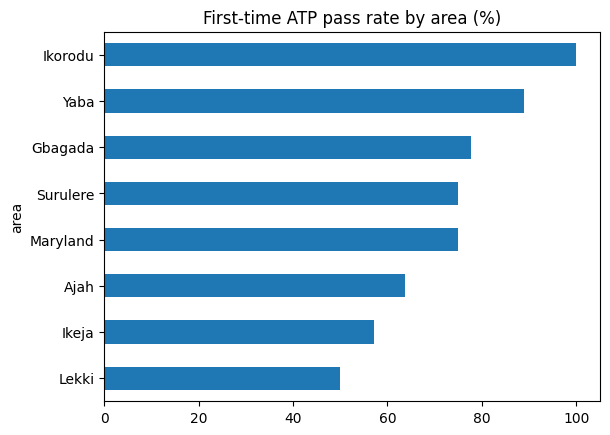

In [4]:
pass_rate = df.groupby('area')['atp_result'].apply(lambda s: (s=='Pass').mean()*100).sort_values()
pass_rate.plot(kind='barh', title='First-time ATP pass rate by area (%)')
plt.show()

## 3. Defect types found at ATP

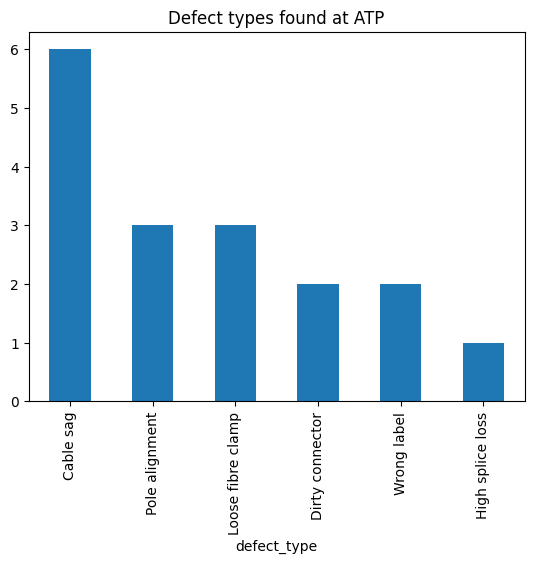

In [5]:
df[df['defect_type']!='None']['defect_type'].value_counts().plot(kind='bar', title='Defect types found at ATP')
plt.show()

## 4. Build time vs site size

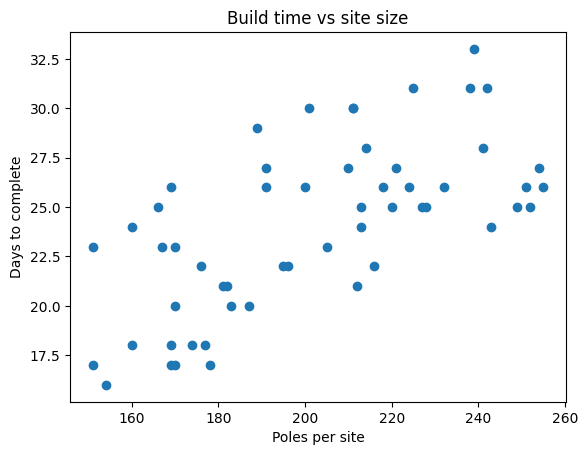

In [6]:
plt.scatter(df['poles'], df['days_to_complete'])
plt.xlabel('Poles per site'); plt.ylabel('Days to complete')
plt.title('Build time vs site size')
plt.show()

## 5. Optical loss distribution

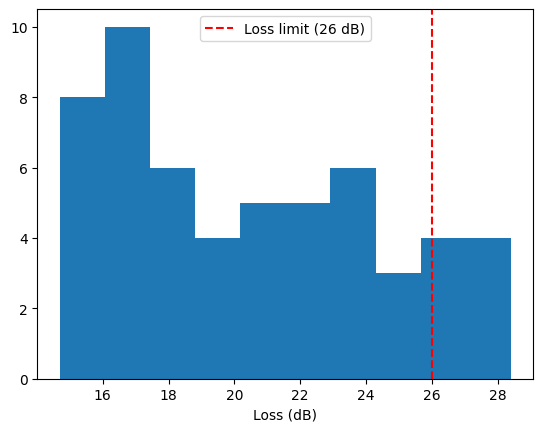

In [7]:
plt.hist(df['loss_db'], bins=10)
plt.axvline(26, color='red', linestyle='--', label='Loss limit (26 dB)')
plt.xlabel('Loss (dB)'); plt.legend(); plt.show()

## Findings
Write 3 findings here in your own words, with numbers (for example: the area with the lowest pass rate, the most common defect, and whether bigger sites take longer).